# Train/test split

A model's score on data it has already seen tells you little. We hide a **test set** and score on that instead. This notebook shows the split, what `random_state` does, and why one split is not the whole story.

This notebook goes with the **Train/test split** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

## 1. Load the data

`customers.csv` is a small made-up table of 80 shoppers: their **country**, **age** and **salary**, and whether they **purchased** (1) or not (0). It was generated for this course, so it is free to use. A few ages and salaries are left blank on purpose.

In [1]:
import numpy as np
import pandas as pd

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/customers.csv"
dataset = pd.read_csv(DATA_URL)
dataset.head()

,country,age,salary,purchased
0,Spain,37.0,49000.0,0
1,France,49.0,52000.0,1
2,France,37.0,35000.0,0
3,Germany,33.0,56500.0,1
4,Germany,24.0,29500.0,0


## 2. Pick the features

We predict `purchased` from `age` and `salary`. Rows with a blank are dropped to keep this notebook focused on the split.

In [2]:
data = dataset.dropna()
X = data[['age', 'salary']].values
y = data['purchased'].values
print(X.shape, 'rows, share who purchased:', y.mean().round(2))

(68, 2) rows, share who purchased: 0.53


## 3. Split

`test_size=0.25` keeps a quarter of the rows for testing. The split is random, and `random_state` is the seed: the same number always gives the same split.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)
print(len(X_train), 'train,', len(X_test), 'test')

# same seed, same split
again = train_test_split(X, y, test_size=0.25, random_state=0)
print('Same split again:', np.array_equal(again[1], X_test))

51 train, 17 test
Same split again: True


## 4. A different seed is a different split

We train the same model on five different splits. The test score moves around, because each split puts different points in the test set. A single score is a **sample**, not the truth.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

scores = []
for seed in range(5):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=seed)
    model = make_pipeline(StandardScaler(), LogisticRegression())
    model.fit(Xtr, ytr)
    scores.append(model.score(Xte, yte))
    print('random_state =', seed, '-> test accuracy', round(scores[-1], 2))

print('Average:', round(np.mean(scores), 2))

random_state = 0 -> test accuracy 0.88
random_state = 1 -> test accuracy 1.0
random_state = 2 -> test accuracy 0.88
random_state = 3 -> test accuracy 0.82
random_state = 4 -> test accuracy 0.76
Average: 0.87


## 5. Change the size of the test set

A bigger test set gives a steadier score but leaves less data to learn from.

In [5]:
for frac in [0.1, 0.25, 0.5]:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=frac, random_state=0)
    model = make_pipeline(StandardScaler(), LogisticRegression()).fit(Xtr, ytr)
    print(f'test_size={frac}: {len(Xtr)} train, {len(Xte)} test, test accuracy {model.score(Xte, yte):.2f}')

test_size=0.1: 61 train, 7 test, test accuracy 0.86


test_size=0.25: 51 train, 17 test, test accuracy 0.88
test_size=0.5: 34 train, 34 test, test accuracy 0.82


## Try it yourself

- Add `stratify=y` to `train_test_split`. It keeps the share of buyers the same in both sets. Does the score change?
- Run step 4 with `range(20)`. How wide is the spread of scores?

## See it: which points are held back

Every dot is a shopper, coloured by whether they bought (blue = no, raspberry = yes). **Filled dots** are the training set, which the model learns from. **Ringed dots** are the test set, which it never sees. The counts are in the title. **Notice how** the test points are scattered randomly among the training points: they are not a separate corner of the data.

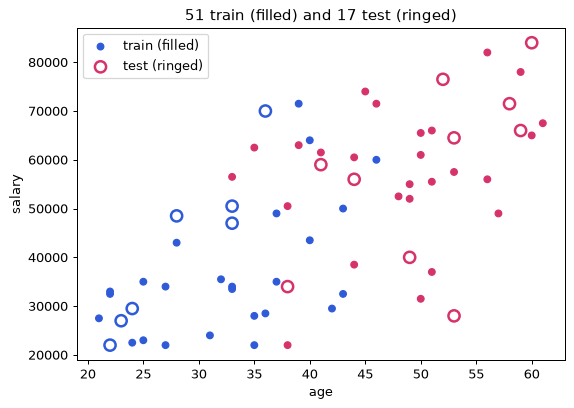

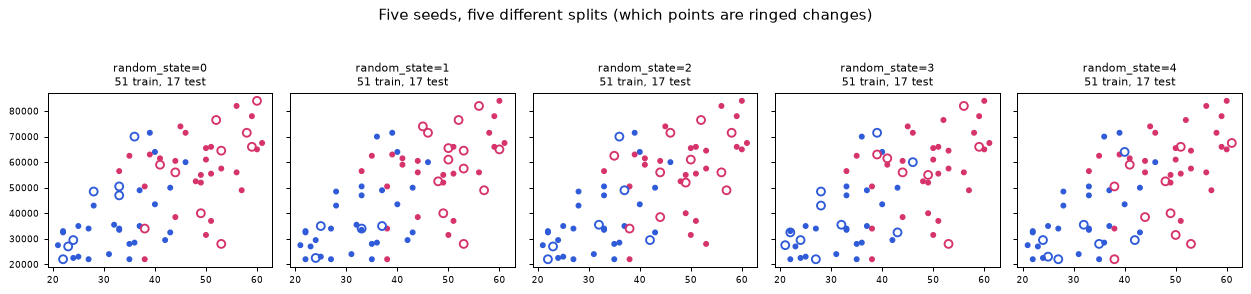

In [6]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

def draw_split(ax, seed, small=False):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=seed)
    colors = [BLUE, PINK]
    ax.scatter(Xtr[:, 0], Xtr[:, 1], c=[colors[v] for v in ytr], s=14 if small else 28, label='train (filled)')
    ax.scatter(Xte[:, 0], Xte[:, 1], facecolors='none', edgecolors=[colors[v] for v in yte],
               s=40 if small else 80, linewidths=1.5 if small else 2, label='test (ringed)')
    ax.set_title(f'random_state={seed}: {len(Xtr)} train, {len(Xte)} test' if small
                 else f'{len(Xtr)} train (filled) and {len(Xte)} test (ringed)')
    return Xtr, Xte

fig, ax = plt.subplots(figsize=(7, 4.8))
draw_split(ax, 0)
ax.set_xlabel('age'); ax.set_ylabel('salary')
ax.legend(loc='upper left')
plt.show()

# Optional: five different seeds give five different splits of the same 60-odd shoppers.
fig, axes = plt.subplots(1, 5, figsize=(14, 3.1), sharex=True, sharey=True)
for seed, ax in enumerate(axes):
    draw_split(ax, seed, small=True)
    ax.set_title(f'random_state={seed}\n{int(len(X) * 0.75)} train, {len(X) - int(len(X) * 0.75)} test', fontsize=9)
    ax.tick_params(labelsize=7)
fig.suptitle('Five seeds, five different splits (which points are ringed changes)', y=1.04)
fig.tight_layout()
plt.show()
